# Lab 1: Fashion-MNIST Classification with PyTorch MLP
## Pipeline Overview, Training, Diagnostics, and Ablations

### Pipeline Stages
| Step | Phase | Core Description | Implementation Module | Output / Artifact |
|:---:|:---|:---|:---|:---|
| **1** | **EDA** | Verify 60k rows, 10 balanced classes, pixel bounds [0, 255], 0 missing values | `labs.lab1.eda` | `class_counts.png`, `sample_grid.png` |
| **2** | **Preprocessing** | Stratified 90/10 split (`seed=42`, exactly 600/class in validation) | `labs.lab1.preprocessing` | `train_val_split.json` |
| **3** | **Features** | Train-only normalization (prevents distribution leakage), PyTorch DataLoaders | `labs.lab1.features` | DataLoaders (batch=64) |
| **4** | **Model** | Fully-connected MLP ($784 \to 256 \to 128 \to 10$, 235k trainable parameters) | `labs.lab1.model` | Model graph & Logits forward pass |
| **5** | **Train** | Adam optimizer, sample-weighted loss accumulation, best validation checkpointing | `labs.lab1.train` | `mlp_baseline.pt` (best val loss) |
| **6** | **Evaluate** | Evaluation without gradient computation (`torch.no_grad`), $10 \times 10$ confusion matrix | `labs.lab1.evaluate` | Validation loss & accuracy |
| **7** | **Detailed Report** | Per-class Precision, Recall (TPR), Specificity (TNR), and F1-Score | `labs.lab1.evaluate` | Per-class metrics table |
| **8** | **Error Analysis** | Visual inspection of misclassified Shirt images and counts of where the errors go | `matplotlib` | 2x4 error grid & rationale |
| **9** | **Visualize** | Training vs validation loss curves, 4x4 predictions grid, CM heatmap | `labs.lab1.visualize` | 3 artifact figures in `figures/` |
| **10** | **Ablations** | 7 configurations, 5 seeds each, compared in pairs that change one factor | `labs.lab1.experiment` | `experiment_results.csv` & plot |
| **11** | **Final Test** | Test evaluation on 10,000 samples, the baseline across 5 seeds, and a 20-epoch study | `labs.lab1.evaluate` | Final test accuracy & loss |
| **App.** | **Appendix** | Multi-class One-vs-Rest ROC & Precision-Recall curves | `sklearn.metrics` | Threshold diagnostic curves |

```mermaid
flowchart TD
    A["Kaggle Fashion-MNIST CSVs<br/>(60k Train, 10k Test)"] --> B["1. Exploratory Data Analysis<br/>(Class distribution & pixel checks)"]
    B --> C["2. Stratified 90/10 Split<br/>(54k Train, 6k Val: 600/class)"]
    C --> D["3. Train-Only Normalization<br/>(Prevents data leakage)"]
    D --> E["4. MLP Architecture<br/>(784 → 256 → 128 → 10: 235k params)"]
    E --> F["5. Training with Sample-Weighted Loss<br/>(Adam lr=1e-3, 5 epochs)"]
    F --> G["Best Checkpoint: mlp_baseline.pt"]
    G --> H["6. Validation Evaluation & Confusion Matrix"]
    G --> I["7. Detailed Classification Report (P/R/F1)"]
    G --> J["8. Error Analysis: Shirt Class"]
    G --> K["9. Visualizations (Loss, Grid, Heatmap)"]
    G --> L["10. Ablation Studies (7 configurations, 5 seeds)"]
    L --> M["11. Final Test Evaluation"]
    M --> N["Appendix: ROC & PR Curves"]
```


### Stage 0: Data Source
- **Dataset**: Fashion-MNIST, a dataset of Zalando's article images: https://github.com/zalandoresearch/fashion-mnist
- **Where we downloaded it**: Kaggle, as CSV files: https://www.kaggle.com/datasets/zalando-research/fashionmnist
- **Size**: 60,000 training and 10,000 test examples, each a 28x28 grayscale image with a label from 10 classes (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot).
- **Why it exists**: its authors intend it as a direct replacement for the original MNIST digits for benchmarking, because MNIST is too easy, overused, and does not represent modern computer vision tasks.
- **File format we use**: `fashion-mnist_train.csv` and `fashion-mnist_test.csv`: one `label` column plus 784 pixel columns (`pixel1` to `pixel784`).
- **License**: MIT, as stated in the Zalando GitHub repository.
- **Citation**: Han Xiao, Kashif Rasul, Roland Vollgraf. *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms*. 2017. arXiv:1708.07747.

---

**Tiếng Việt**

- **Bộ dữ liệu**: Fashion-MNIST, gồm ảnh sản phẩm của Zalando: https://github.com/zalandoresearch/fashion-mnist
- **Nơi nhóm tải về**: Kaggle, dạng file CSV: https://www.kaggle.com/datasets/zalando-research/fashionmnist
- **Kích thước**: 60.000 mẫu train và 10.000 mẫu test, mỗi mẫu là một ảnh xám 28x28 có nhãn thuộc 10 lớp.
- **Vì sao có bộ này**: tác giả muốn thay thế trực tiếp MNIST chữ số để đánh giá thuật toán, vì MNIST quá dễ, bị dùng quá nhiều và không đại diện cho các bài toán thị giác máy tính hiện đại.
- **Định dạng nhóm dùng**: `fashion-mnist_train.csv` và `fashion-mnist_test.csv`: một cột `label` và 784 cột pixel (`pixel1` đến `pixel784`).
- **Giấy phép**: MIT, theo repo GitHub của Zalando.
- **Trích dẫn**: như phần tiếng Anh ở trên.

**Checked against the official files (2026-11-01):** the Kaggle CSVs do not follow the official split. Of the 9,999 distinct images in the Kaggle test file, 7,918 come from the official training set, 1,291 from the official test set, and about 790 have no exact match. Scores here are valid for these CSVs but cannot be compared directly with published results. The cause is unknown.


In [1]:
import sys
from pathlib import Path
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# 1. Dynamic Repository Root Resolution
cwd = Path.cwd().resolve()
repo_root = cwd
for p in [cwd] + list(cwd.parents):
    if (p / 'shared').is_dir() and (p / 'labs').is_dir():
        repo_root = p
        break

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# 2. Module Imports (Clean, strictly from shared and labs.lab1)
from shared.paths import raw_data_dir, artifact_dir
from shared.seed import set_seed
from labs.lab1.eda.eda import run_eda
from labs.lab1.preprocessing.preprocessing import load_csv, load_split, make_split, save_split
from labs.lab1.features.features import compute_mean_std, build_transform, FashionDataset, make_loaders
from labs.lab1.model.model import MLP, count_parameters
from labs.lab1.train.train import train_model, load_checkpoint
from labs.lab1.evaluate.evaluate import evaluate, confusion_matrix, per_class_accuracy, save_classification_report
from labs.lab1.visualize.visualize import plot_loss_curves, show_predictions, plot_confusion_matrix
from labs.lab1.experiment.experiment import compare_pairs
from labs.lab1.main import N_THREADS

# 3. Seed & Hardware Setup (same CPU thread count as main.py)
torch.set_num_threads(N_THREADS)
set_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

CLASS_NAMES = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print(f'Repository root  : {repo_root.name}')
print(f'Execution device : {device} | CPU threads: {N_THREADS}')


Repository root  : Lab-DL
Execution device : cpu | CPU threads: 4


### Stage 1: Exploratory Data Analysis (`labs.lab1.eda`)
We inspect the raw training CSV (`fashion-mnist_train.csv`) to verify dataset integrity without modifying any values:
- **Row count & class balance**: Exactly 60,000 rows across 10 balanced categories (6,000 samples per class).
- **Pixel validity**: All pixel values fall strictly in the $[0, 255]$ grayscale range with 0 missing (NaN) values.
- **Duplicates**: 43 duplicate rows exist in the Kaggle CSV. We keep them (team decision). Identical images also remain across splits: train-val 9, train-test 9, val-test 1 (see README, Limitation).

*Note on Class Balance*: Balanced classes ensure overall accuracy serves as a reliable performance indicator without majority-class bias.

Total samples : 60,000
Missing values: 0 | Duplicate rows: 43
Class distribution: {0: 6000, 1: 6000, 2: 6000, 3: 6000, 4: 6000, 5: 6000, 6: 6000, 7: 6000, 8: 6000, 9: 6000}


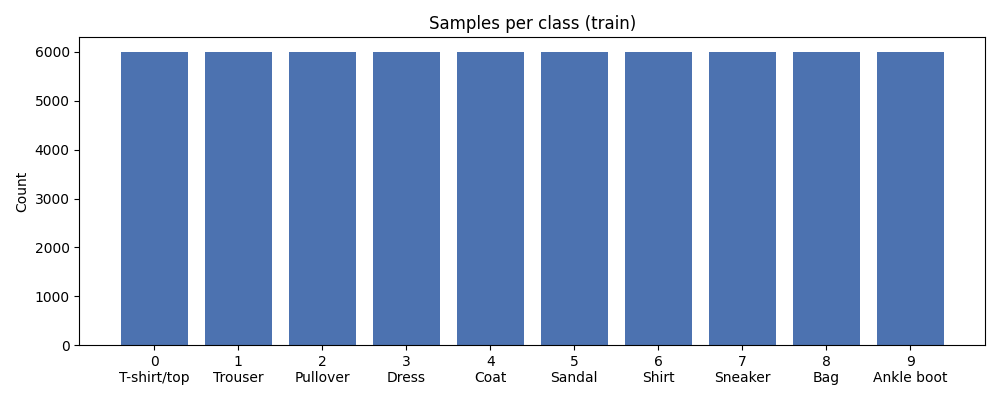

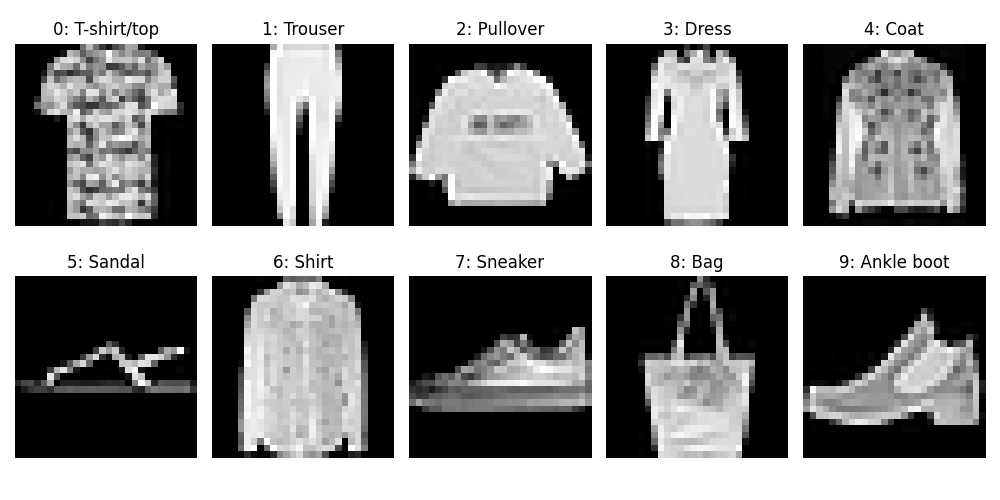

In [2]:
train_csv_path = str(raw_data_dir('lab1') / 'fashion-mnist_train.csv')
figures_dir = artifact_dir('lab1', 'figures')

eda_stats = run_eda(train_csv_path, str(figures_dir))
print(f"Total samples : {eda_stats['n_rows']:,}")
print(f"Missing values: {eda_stats['n_missing']} | Duplicate rows: {eda_stats['n_duplicates']}")
print("Class distribution:", eda_stats['class_counts'])

display(Image(filename=str(figures_dir / 'class_counts.png')))
display(Image(filename=str(figures_dir / 'sample_grid.png')))


### Stage 2: Preprocessing & Stratified Splitting (`labs.lab1.preprocessing`)
We load pixel values as `uint8 [N, 28, 28]` and labels as `int64 [N]`.
We construct a reproducible 90/10 stratified split (`seed=42`):
- **Training set**: 54,000 samples (5,400 per class).
- **Validation set**: 6,000 samples (exactly 600 per class).
- **Persistence**: Indices are saved to `train_val_split.json` so that all modules and teammates use the exact same partition.

*Why Stratified Splitting?* Stratification enforces identical class proportions across both training and validation sets, preventing random sampling skew.

In [3]:
test_csv_path = str(raw_data_dir('lab1') / 'fashion-mnist_test.csv')
splits_dir = artifact_dir('lab1', 'splits')
split_file = str(splits_dir / 'train_val_split.json')

images, labels = load_csv(train_csv_path)
test_images, test_labels = load_csv(test_csv_path)

if Path(split_file).is_file():
    train_idx, val_idx = load_split(split_file)
else:
    train_idx, val_idx = make_split(labels, val_ratio=0.1, seed=42)
    save_split(train_idx, val_idx, split_file)

print(f"Train images shape : {images.shape}, dtype: {images.dtype}")
print(f"Split partitions   : Train = {len(train_idx):,} | Val = {len(val_idx):,} | Test = {len(test_labels):,}")

val_labels = labels[val_idx]
_, counts = np.unique(val_labels, return_counts=True)
print(f"Validation samples per class (all 600): {dict(enumerate(counts))}")


Train images shape : (60000, 28, 28), dtype: uint8
Split partitions   : Train = 54,000 | Val = 6,000 | Test = 10,000
Validation samples per class (all 600): {0: np.int64(600), 1: np.int64(600), 2: np.int64(600), 3: np.int64(600), 4: np.int64(600), 5: np.int64(600), 6: np.int64(600), 7: np.int64(600), 8: np.int64(600), 9: np.int64(600)}


### Stage 3: Feature Engineering & DataLoaders (`labs.lab1.features`)
We standardize pixel values to zero mean and unit variance:
- **Train-Only Normalization**: Mean ($\mu$) and standard deviation ($\sigma$) are computed **strictly from the 54,000 training images**. The identical transform is applied to validation and test images.
- **Data Leakage Prevention**: Calculating normalization statistics across the entire dataset would leak distribution parameters from unseen sets into the model.
- Images are cast to PyTorch `float32` tensors `[1, 28, 28]` and loaded with `batch_size = 64` (shuffled only during training).

In [4]:
mean, std = compute_mean_std(images[train_idx])
transform = build_transform(mean, std)
print(f"Train-only Normalization Stats: mean = {mean:.4f}, std = {std:.4f}")

train_ds = FashionDataset(images, labels, indices=train_idx, transform=transform)
val_ds = FashionDataset(images, labels, indices=val_idx, transform=transform)
test_ds = FashionDataset(test_images, test_labels, indices=None, transform=transform)

train_loader, val_loader, test_loader = make_loaders(train_ds, val_ds, test_ds, batch_size=64)

# Verify a sample batch
sample_batch_x, sample_batch_y = next(iter(train_loader))
print(f"Batch X tensor shape   : {sample_batch_x.shape}, dtype: {sample_batch_x.dtype}")
print(f"Batch Y tensor shape   : {sample_batch_y.shape}, dtype: {sample_batch_y.dtype}")
print(f"Batch normalized range : min = {sample_batch_x.min():.2f}, max = {sample_batch_x.max():.2f}")


Train-only Normalization Stats: mean = 0.2860, std = 0.3527
Batch X tensor shape   : torch.Size([64, 1, 28, 28]), dtype: torch.float32
Batch Y tensor shape   : torch.Size([64]), dtype: torch.int64
Batch normalized range : min = -0.81, max = 2.02


### Stage 4: Model Architecture & Parameter Audit (`labs.lab1.model`)
We construct a fully-connected Multi-Layer Perceptron (MLP):
- **Input**: Flattened $28 \times 28 = 784$ grayscale image vector.
- **Hidden Layer 1**: Linear(784, 256) + ReLU $\to 784 \times 256 + 256 = 200,960$ parameters.
- **Hidden Layer 2**: Linear(256, 128) + ReLU $\to 256 \times 128 + 128 = 32,896$ parameters.
- **Output Layer**: Linear(128, 10) $\to 128 \times 10 + 10 = 1,290$ parameters.
- **Total Trainable Parameters**: $200,960 + 32,896 + 1,290 = 235,146$.

```mermaid
flowchart LR
    In["Input<br/>[B, 1, 28, 28]"] --> Flat["Flatten<br/>[B, 784]"]
    Flat --> L1["Linear(784, 256)"] --> R1["ReLU"]
    R1 --> L2["Linear(256, 128)"] --> R2["ReLU"]
    R2 --> L3["Linear(128, 10)"] --> Out["Raw Logits<br/>[B, 10]"]
```

*Why Raw Logits?* The model outputs unscaled logits rather than Softmax probabilities because `torch.nn.CrossEntropyLoss` combines `LogSoftmax` and `NLLLoss` internally, providing superior numerical stability.

In [5]:
# Reset seed prior to instantiation for deterministic weight initialization
set_seed(42)
model = MLP(hidden_sizes=(256, 128), num_classes=10, dropout=0.0).to(device)
total_params = count_parameters(model)

print(model)
print(f"\nTotal trainable parameters: {total_params:,}")

# Verify forward pass. zeros uses no random numbers, so training stays identical to main.py
dummy_input = torch.zeros(4, 1, 28, 28, device=device)
dummy_logits = model(dummy_input)
print(f"Dummy output logits shape : {dummy_logits.shape} (expected [4, 10])")


MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

Total trainable parameters: 235,146
Dummy output logits shape : torch.Size([4, 10]) (expected [4, 10])


### Stage 5: Training Baseline Model (`labs.lab1.train`)
We train the baseline model for 5 epochs:
- **Optimization**: Adam optimizer with learning rate $\text{lr} = 10^{-3}$ and `weight_decay = 0.0`.
- **Sample-Weighted Loss**: Per-batch losses are weighted by batch size (`loss.item() * batch_size`) and divided by total samples, ensuring exact epoch loss even if the final batch has fewer than 64 samples.
- **Checkpoint Selection**: The best model weights are checkpointed to `artifacts/models/mlp_baseline.pt` from the epoch with the lowest validation loss among the 5 epochs.

In [6]:
models_dir = artifact_dir('lab1', 'models')
ckpt_path = str(models_dir / 'mlp_baseline.pt')

epochs = 5
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=epochs,
    lr=1e-3,
    device=device,
    ckpt_path=ckpt_path,
    optimizer_name='adam',
    weight_decay=0.0
)

print(f"\nCheckpoint saved to: {Path(ckpt_path).relative_to(repo_root)}")
print("Training history across epochs:")
for ep in range(epochs):
    t_loss = history['train_loss'][ep]
    v_loss = history['val_loss'][ep]
    v_acc = history['val_acc'][ep]
    print(f"  Epoch {ep+1}/{epochs}: Train Loss = {t_loss:.4f} | Val Loss = {v_loss:.4f} | Val Acc = {v_acc*100:.2f}%")



Checkpoint saved to: labs\lab1\artifacts\models\mlp_baseline.pt
Training history across epochs:
  Epoch 1/5: Train Loss = 0.4754 | Val Loss = 0.3870 | Val Acc = 86.02%
  Epoch 2/5: Train Loss = 0.3562 | Val Loss = 0.3430 | Val Acc = 87.62%
  Epoch 3/5: Train Loss = 0.3175 | Val Loss = 0.3197 | Val Acc = 88.22%
  Epoch 4/5: Train Loss = 0.2920 | Val Loss = 0.3199 | Val Acc = 88.67%
  Epoch 5/5: Train Loss = 0.2720 | Val Loss = 0.3031 | Val Acc = 89.38%


### Stage 6: Validation Evaluation & Confusion Matrix (`labs.lab1.evaluate`)
We reload the saved best checkpoint using `load_checkpoint` (evaluation mode, no gradients computed, using `torch.no_grad`).
We compute overall validation loss, validation accuracy, and the $10 \times 10$ confusion matrix.
We also construct a detailed per-class diagnostic report:
- **Precision**: $\frac{TP}{TP + FP}$ — exactness of positive predictions.
- **Recall (TPR)**: $\frac{TP}{TP + FN}$ — proportion of actual positives correctly identified.
- **Specificity (TNR)**: $\frac{TN}{TN + FP}$ — proportion of actual negatives correctly rejected.
- **F1-Score**: Harmonic mean of Precision and Recall: $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$.

In [7]:
eval_model = MLP(hidden_sizes=(256, 128), num_classes=10, dropout=0.0)
best_model = load_checkpoint(eval_model, ckpt_path, device=device)

val_loss, val_acc = evaluate(best_model, val_loader, device=device)
cm = confusion_matrix(best_model, val_loader, device=device, num_classes=10)

# Per-class report, saved by labs.lab1.evaluate
runs_dir = artifact_dir('lab1', 'runs')
df_report = save_classification_report(cm, CLASS_NAMES, str(runs_dir / 'classification_report.csv'))
df_report_view = df_report.copy()
for col in ['precision', 'recall', 'specificity', 'f1']:
    df_report_view[col] = (df_report_view[col] * 100).map('{:.2f}%'.format)

print(f"Validation Loss    : {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc*100:.2f}% ({int(round(val_acc*len(val_ds)))}/{len(val_ds)})")
print("\n=== Per-class Classification Report (Validation Split) ===")
display(df_report_view)


Validation Loss    : 0.3031
Validation Accuracy: 89.38% (5363/6000)

=== Per-class Classification Report (Validation Split) ===


,class,support,precision,recall,specificity,f1
0,T-shirt/top,600,79.79%,88.83%,97.50%,84.07%
1,Trouser,600,98.01%,98.33%,99.78%,98.17%
2,Pullover,600,81.79%,80.83%,98.00%,81.31%
3,Dress,600,88.52%,88.67%,98.72%,88.59%
4,Coat,600,78.83%,85.00%,97.46%,81.80%
5,Sandal,600,96.96%,95.83%,99.67%,96.40%
6,Shirt,600,81.22%,66.33%,98.30%,73.03%
7,Sneaker,600,94.44%,96.33%,99.37%,95.38%
8,Bag,600,97.48%,96.83%,99.72%,97.16%
9,Ankle boot,600,97.16%,96.83%,99.69%,96.99%


### Stage 7: Error Analysis — Shirt Misclassification Study
In the classification report above, **Shirt (Class 6)** has the lowest recall in this run (66.33%, F1 73.03%) and in 4 of 5 seeds (see Stage 10).
We extract and visually inspect validation samples of the Shirt class that were incorrectly predicted by the model.

**Possible reasons (hypotheses, not tested):**
1. **Low-resolution pixel degradation (28x28 grayscale)**: Critical visual markers distinguishing a buttoned shirt (collar folds, button placket, cuffs) become blurred after downsampling.
2. **Silhouette and texture overlap**: The overall shape of a Shirt strongly resembles `T-shirt/top`, `Pullover`, and `Coat`.
3. **No built-in local structure**: The MLP flattens each image into 784 numbers, so it has no built-in way to use neighbouring pixels, unlike a CNN.


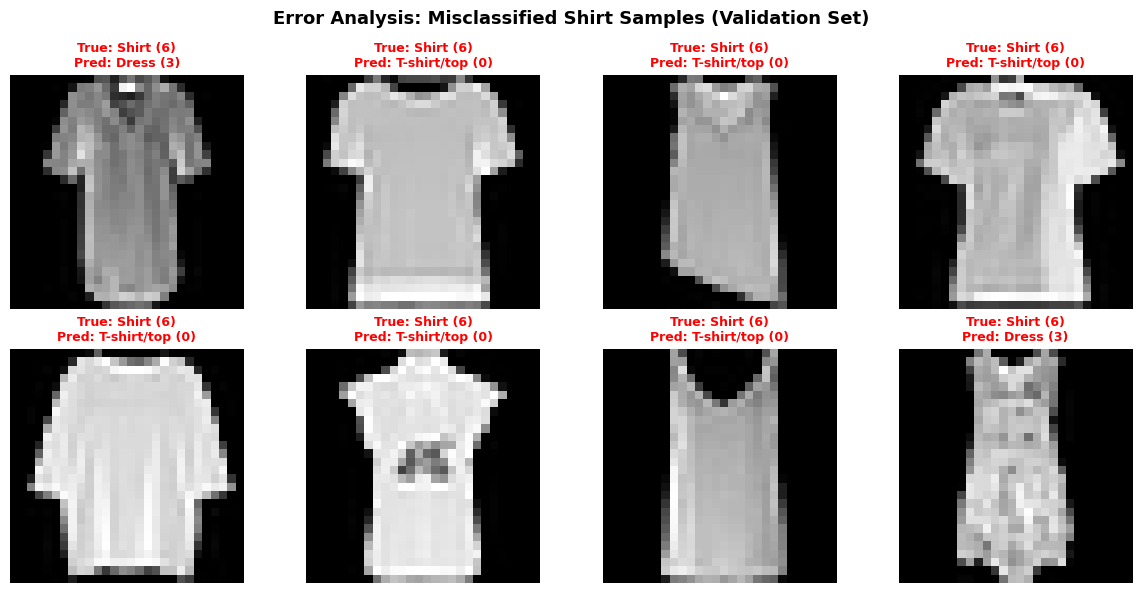

Shirt: 398/600 correct, 202 misclassified.
Top-3 wrong predictions for true Shirt samples:
  1. T-shirt/top (class 0): 92 samples (15.33% of Shirt, 45.54% of Shirt errors)
  2. Pullover (class 2): 47 samples (7.83% of Shirt, 23.27% of Shirt errors)
  3. Coat (class 4): 44 samples (7.33% of Shirt, 21.78% of Shirt errors)


In [8]:
shirt_class_id = 6
misclassified_shirts = []

best_model.eval()
with torch.no_grad():
    for x_b, y_b in val_loader:
        logits = best_model(x_b.to(device))
        preds = torch.argmax(logits, dim=1).cpu()
        for img, true_lbl, pred_lbl in zip(x_b, y_b, preds):
            if true_lbl.item() == shirt_class_id and pred_lbl.item() != shirt_class_id:
                # Un-normalize image: x_raw = x_norm * std + mean
                img_raw = (img.squeeze(0).cpu().numpy() * std + mean).clip(0, 1)
                misclassified_shirts.append((img_raw, pred_lbl.item()))
            if len(misclassified_shirts) >= 8:
                break
        if len(misclassified_shirts) >= 8:
            break

# Plot 2x4 grid of misclassified shirt images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for idx, (img_arr, p_lbl) in enumerate(misclassified_shirts[:8]):
    ax = axes[idx // 4, idx % 4]
    ax.imshow(img_arr, cmap='gray')
    ax.set_title(f"True: Shirt (6)\nPred: {CLASS_NAMES[p_lbl]} ({p_lbl})", color='red', fontsize=9, fontweight='bold')
    ax.axis('off')

plt.suptitle("Error Analysis: Misclassified Shirt Samples (Validation Set)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Error breakdown from the Shirt row of the confusion matrix, diagonal (correct predictions) excluded
shirt_row = cm[shirt_class_id]
n_shirt = int(shirt_row.sum())
errors = shirt_row.copy()
errors[shirt_class_id] = 0
n_err = int(errors.sum())
print(f"Shirt: {int(shirt_row[shirt_class_id])}/{n_shirt} correct, {n_err} misclassified.")
print("Top-3 wrong predictions for true Shirt samples:")
for rank, c_idx in enumerate(np.argsort(-errors)[:3], 1):
    count = int(errors[c_idx])
    print(f"  {rank}. {CLASS_NAMES[c_idx]} (class {c_idx}): {count} samples "
          f"({count / n_shirt * 100:.2f}% of Shirt, {count / n_err * 100:.2f}% of Shirt errors)")


### Stage 8: Visual Diagnostics (`labs.lab1.visualize`)
We generate and visually inspect three primary diagnostic figures:
1. **Loss Curves**: Training vs validation loss trajectories over 5 epochs. Val loss is lowest at epoch 5 (0.3031) and the best epoch is the last one in 4 of 5 seeds, so these 5 epochs show no rise in val loss that would point to overfitting.
2. **Predictions Grid**: 16 validation samples with predicted and ground-truth labels (green for correct, red for errors).
3. **Confusion Matrix Heatmap**: Annotated cell counts showing where classification errors concentrate.

1. Loss Curves Trajectory:


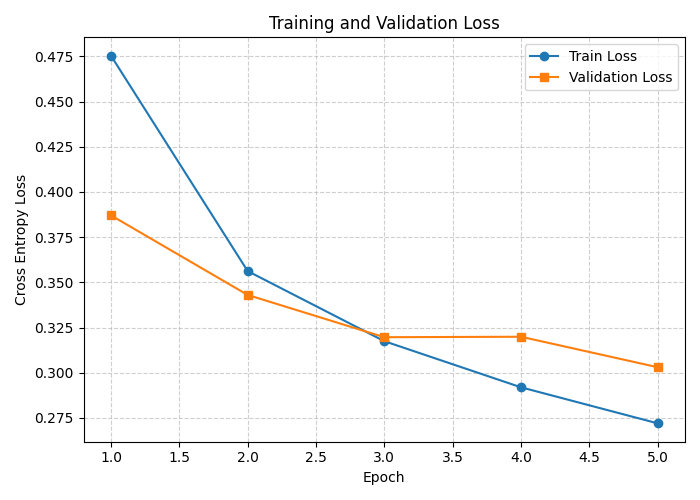


2. Sample Predictions Grid (Green = Correct, Red = Error):


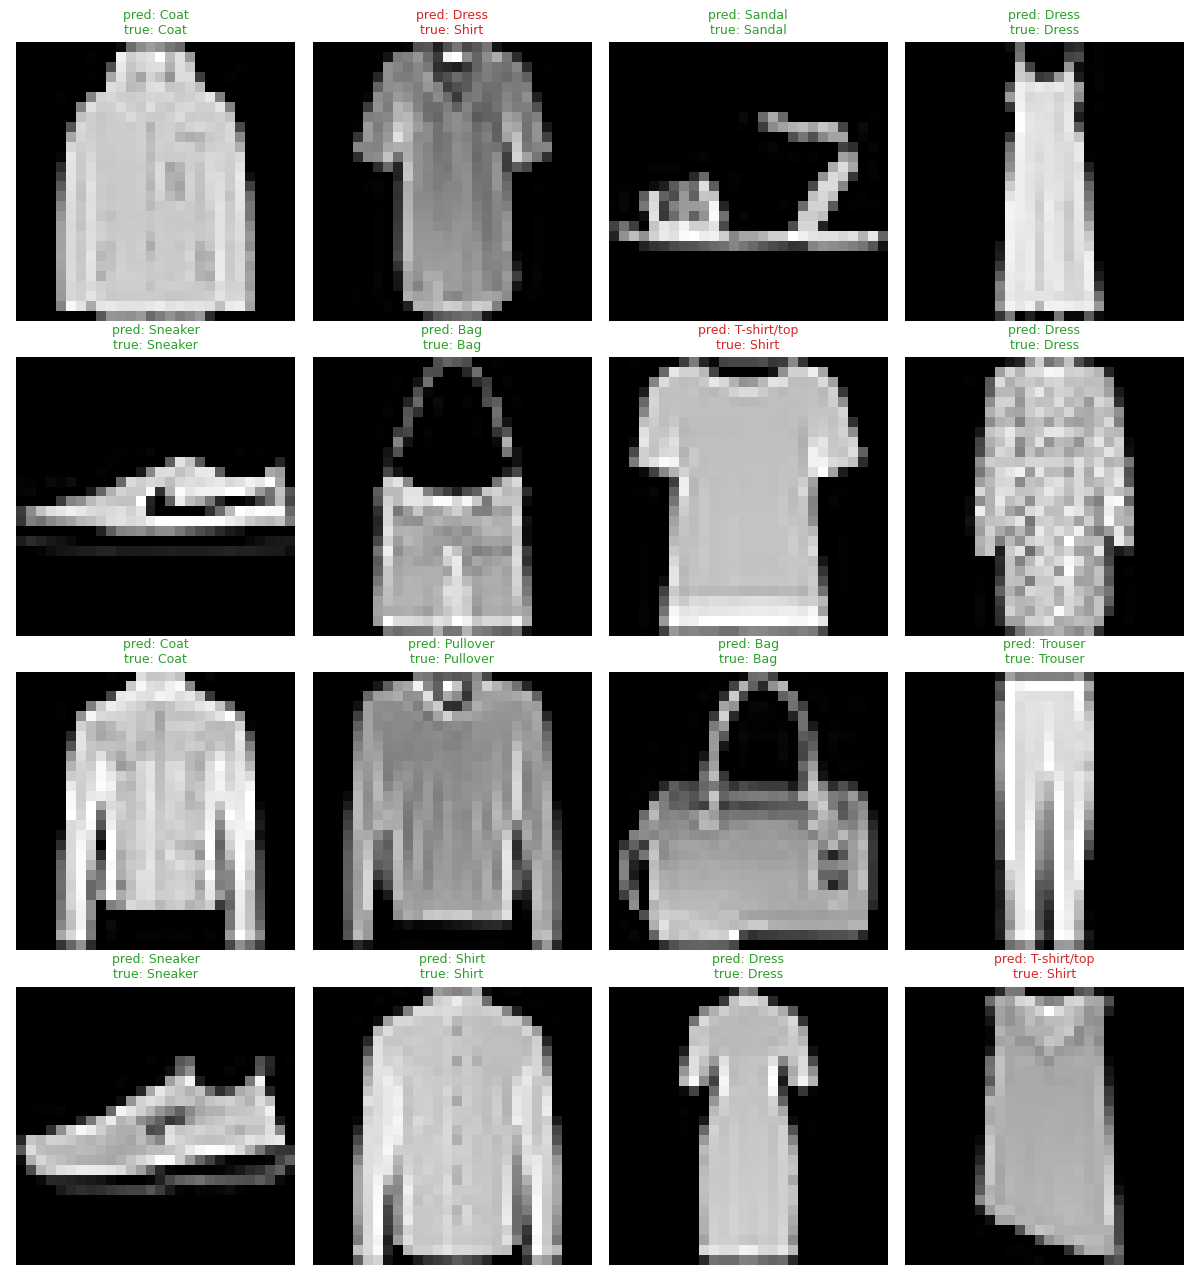


3. Confusion Matrix Heatmap:


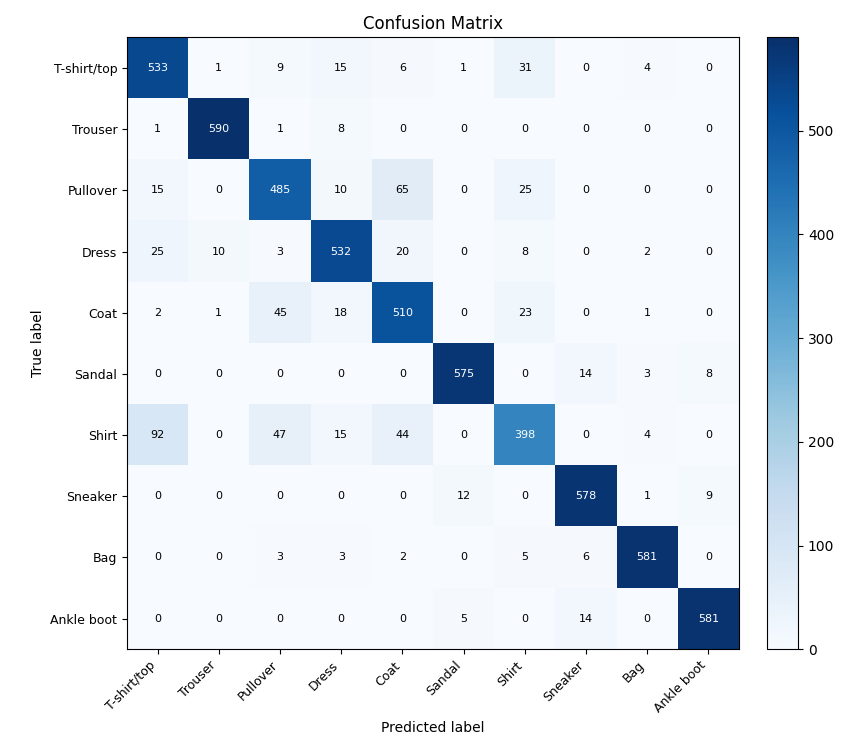

In [9]:
loss_fig_path = str(figures_dir / 'loss_curves.png')
pred_fig_path = str(figures_dir / 'predictions_grid.png')
cm_fig_path = str(figures_dir / 'confusion_matrix.png')

plot_loss_curves(history, loss_fig_path)
show_predictions(best_model, val_loader, CLASS_NAMES, device=device, out_path=pred_fig_path, n=16)
plot_confusion_matrix(cm, CLASS_NAMES, cm_fig_path)

print("1. Loss Curves Trajectory:")
display(Image(filename=loss_fig_path))

print("\n2. Sample Predictions Grid (Green = Correct, Red = Error):")
display(Image(filename=pred_fig_path))

print("\n3. Confusion Matrix Heatmap:")
display(Image(filename=cm_fig_path))


### Stage 9: Ablation Experiments (`labs.lab1.experiment`)
This cell reads the results of `python -m labs.lab1.main`, so run `main.py` first. Each configuration ran with 5 seeds (42, 7, 123, 2024, 3407) on the same split. Every value is the validation accuracy of the checkpoint that was kept (lowest val loss).

| Configuration | Change | Question |
|---|---|---|
| `baseline` | 256-128, Adam, lr=1e-3 | Reference |
| `softmax_regression` | No hidden layer | What do hidden layers add? |
| `sgd_same_lr` | SGD (momentum 0.9), same lr | Optimizer |
| `sgd_lr_0.01` | `sgd_same_lr` with lr=0.01 | Learning rate |
| `larger_network` | 512-256-128 | Network size |
| `dropout_0.2` | Dropout 0.2 | Dropout |
| `weight_decay_1e-4` | Weight decay 1e-4 | Weight decay |

**Rule, fixed before reading the results:** a pair shows a clear difference only if all 5 seeds point the same way and the mean difference is at least twice its standard deviation. A paired t-test with Holm correction for 6 comparisons and a 95% confidence interval are added as a second check. Selection uses validation data only.

**Reading the table:** hidden layers, the optimizer and the learning rate show clear differences. The larger network, dropout and weight decay do not pass either check within 5 epochs (dropout: p = 0.031 before correction, 0.093 after). With 5 seeds this is not proof of no effect.


=== Validation accuracy across 5 seeds (%) ===


,hidden,optimizer,lr,dropout,weight_decay,params,seeds,val_acc_mean,val_acc_std,train_seconds
name,,,,,,,,,,
baseline,256-128,adam,0.001,0.0,0.0000,235146,5,88.82,0.39,20.7
softmax_regression,none,adam,0.001,0.0,0.0000,7850,5,85.07,0.14,13.2
sgd_same_lr,256-128,sgd,0.001,0.0,0.0000,235146,5,85.49,0.31,20.0
sgd_lr_0.01,256-128,sgd,0.010,0.0,0.0000,235146,5,88.31,0.45,17.1
larger_network,512-256-128,adam,0.001,0.0,0.0000,567434,5,88.49,0.25,48.9
dropout_0.2,256-128,adam,0.001,0.2,0.0000,235146,5,88.15,0.33,19.0
weight_decay_1e-4,256-128,adam,0.001,0.0,0.0001,235146,5,88.52,0.37,18.7



=== Paired differences in validation accuracy (points) ===


,factor,variant,mean_diff,std_diff,ci95_low,ci95_high,seeds_higher,rule_clear,p_value,p_holm
0,hidden layers,softmax_regression,-3.75,0.45,-4.31,-3.19,0,True,0.0001,0.0003
1,optimizer,sgd_same_lr,-3.33,0.34,-3.75,-2.91,0,True,0.0000,0.0002
2,learning rate,sgd_lr_0.01,2.81,0.38,2.35,3.28,5,True,0.0001,0.0003
3,network size,larger_network,-0.34,0.48,-0.93,0.26,1,False,0.1911,0.2755
4,dropout,dropout_0.2,-0.68,0.46,-1.25,-0.10,0,False,0.0309,0.0927
5,weight decay,weight_decay_1e-4,-0.30,0.37,-0.76,0.15,1,False,0.1378,0.2755


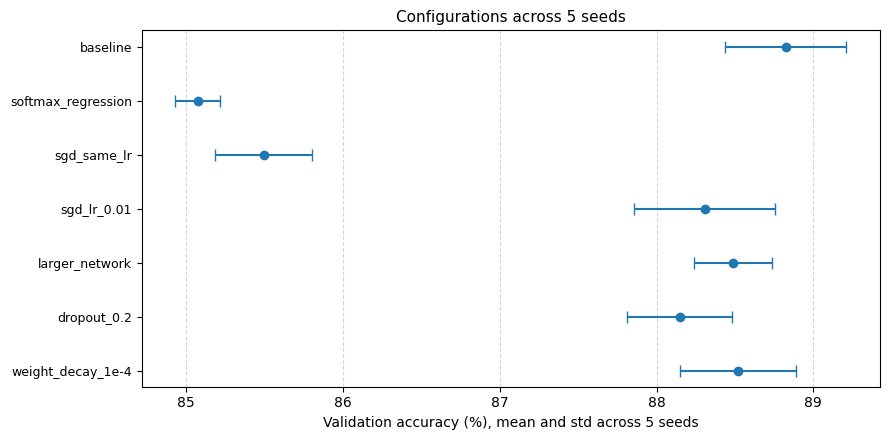

In [10]:
# Results come from `python -m labs.lab1.main` (35 runs), so the notebook only reads them
exp = pd.read_csv(runs_dir / 'experiment_results.csv', keep_default_na=False)
exp['val_acc_pct'] = exp['best_val_acc'] * 100

summary = exp.groupby('name', sort=False).agg(
    hidden=('hidden_sizes', 'first'),
    optimizer=('optimizer_name', 'first'),
    lr=('lr', 'first'),
    dropout=('dropout', 'first'),
    weight_decay=('weight_decay', 'first'),
    params=('n_params', 'first'),
    seeds=('seed', 'count'),
    val_acc_mean=('val_acc_pct', 'mean'),
    val_acc_std=('val_acc_pct', 'std'),
    train_seconds=('train_seconds', 'mean'),
)
print('=== Validation accuracy across 5 seeds (%) ===')
display(summary.round({'val_acc_mean': 2, 'val_acc_std': 2, 'train_seconds': 1}))

# Paired comparison: each pair differs in one factor and shares the same 5 seeds
pairs = [
    ('softmax_regression', 'baseline', 'hidden layers'),
    ('sgd_same_lr', 'baseline', 'optimizer'),
    ('sgd_lr_0.01', 'sgd_same_lr', 'learning rate'),
    ('larger_network', 'baseline', 'network size'),
    ('dropout_0.2', 'baseline', 'dropout'),
    ('weight_decay_1e-4', 'baseline', 'weight decay'),
]
acc_by_seed = exp.pivot(index='seed', columns='name', values='val_acc_pct')
df_pairs = compare_pairs(acc_by_seed, pairs)
print('\n=== Paired differences in validation accuracy (points) ===')
display(df_pairs.drop(columns='reference').round({'mean_diff': 2, 'std_diff': 2, 'ci95_low': 2, 'ci95_high': 2, 'p_value': 4, 'p_holm': 4}))

# Mean and spread across seeds; the axis does not start at 0, read the numbers
fig, ax = plt.subplots(figsize=(9, 4.5))
y_pos = np.arange(len(summary))[::-1]
ax.errorbar(summary['val_acc_mean'], y_pos, xerr=summary['val_acc_std'], fmt='o', color='#1f77b4', capsize=4)
ax.set_yticks(y_pos)
ax.set_yticklabels(summary.index, fontsize=9)
ax.set_xlabel('Validation accuracy (%), mean and std across 5 seeds', fontsize=10)
ax.set_title('Configurations across 5 seeds', fontsize=11)
ax.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Stage 10: Final Test Set Evaluation
The test set (`fashion-mnist_test.csv`, 10,000 samples) is used only to report results. The baseline was fixed before the experiments, and no choice in this notebook uses a test score.

The first block is the saved model (seed 42). The tables report the same configuration across 5 seeds, which is the better estimate because one seed can be lucky. Recall and confusions use validation data.

`main.py` and this notebook were run several times during development, so the test set was seen more than once in practice.

**Extended study (20 epochs, 5 seeds; run `python -m labs.lab1.extended_study` first).** It answers two limits of the 5-epoch runs: does the baseline overfit later, and does dropout need more epochs? The test set is reported only for the baseline, fixed before the run.


In [11]:
test_loss, test_acc = evaluate(best_model, test_loader, device=device)

print("============================================================")
print("           FINAL TEST SET EVALUATION RESULTS                ")
print("============================================================")
print(f"  Dataset Partition : Kaggle Fashion-MNIST Test Split (10,000 samples)")
print(f"  Model Checkpoint  : {Path(ckpt_path).relative_to(repo_root)}")
print(f"  Test Loss         : {test_loss:.4f}")
print(f"  Test Accuracy     : {test_acc*100:.2f}% ({int(round(test_acc*len(test_ds)))}/{len(test_ds)} correct)")
print("============================================================")

# Baseline across 5 seeds: fixed beforehand, so the test set selects nothing
seed_df = pd.read_csv(runs_dir / 'seed_results.csv')
recall_df = pd.read_csv(runs_dir / 'recall_by_class.csv')
confusion_df = pd.read_csv(runs_dir / 'top_confusions.csv')

test_pct = seed_df['test_acc'] * 100
sampling_ci = 1.96 * np.sqrt(seed_df['test_acc'].mean() * (1 - seed_df['test_acc'].mean()) / len(test_ds)) * 100
print(f"\nBaseline test accuracy across {len(seed_df)} seeds: {test_pct.mean():.2f} +/- {test_pct.std():.2f}%")
print(f"Sampling error of one test score (95%): +/- {sampling_ci:.2f} points")
display(seed_df.round(4))

print('Recall by class across seeds (validation):')
display(recall_df.sort_values('recall_mean').round(4))

print('Most frequent confusions, summed over seeds (validation):')
display(confusion_df)

train_pct = seed_df['train_acc'] * 100
print(f"Train accuracy of the same checkpoints: {train_pct.mean():.2f}%, gap to validation: {(train_pct - seed_df['val_acc'] * 100).mean():.2f} points")

# Extended study (20 epochs): results of `python -m labs.lab1.extended_study`
ext = pd.read_csv(runs_dir / 'extended_results.csv')
ext_summary = ext.groupby('name', sort=False).agg(
    best_epoch_min=('best_epoch', 'min'),
    best_epoch_max=('best_epoch', 'max'),
    val_acc_mean=('best_val_acc', lambda s: s.mean() * 100),
    val_acc_std=('best_val_acc', lambda s: s.std() * 100),
    best_val_loss=('best_val_loss', 'mean'),
    final_val_loss=('final_val_loss', 'mean'),
)
print('\n=== 20 epochs, 5 seeds ===')
display(ext_summary.round(4))

ext_test = pd.read_csv(runs_dir / 'baseline_20_seed_results.csv')['test_acc'] * 100
print(f"20-epoch baseline test accuracy: {ext_test.mean():.2f} +/- {ext_test.std():.2f}%")

ext_acc = ext.assign(pct=ext['best_val_acc'] * 100).pivot(index='seed', columns='name', values='pct')
ext_acc['baseline_5'] = acc_by_seed['baseline']
ext_loss = ext.pivot(index='seed', columns='name', values='final_val_loss') * 100
long_pairs = compare_pairs(ext_acc, [('baseline_20', 'baseline_5', '20 vs 5 epochs (val acc, points)'),
                                     ('dropout_0.2_20', 'baseline_20', 'dropout (val acc, points)')])
loss_pairs = compare_pairs(ext_loss, [('dropout_0.2_20', 'baseline_20', 'dropout (final val loss x 100)')])
display(pd.concat([long_pairs, loss_pairs]).drop(columns='reference').round(4))


           FINAL TEST SET EVALUATION RESULTS                
  Dataset Partition : Kaggle Fashion-MNIST Test Split (10,000 samples)
  Model Checkpoint  : labs\lab1\artifacts\models\mlp_baseline.pt
  Test Loss         : 0.3005
  Test Accuracy     : 88.97% (8897/10000 correct)

Baseline test accuracy across 5 seeds: 88.42 +/- 0.37%
Sampling error of one test score (95%): +/- 0.63 points


,seed,best_epoch,train_loss,train_acc,val_loss,val_acc,test_loss,test_acc
0,42,5,0.2372,0.9115,0.3031,0.8938,0.3005,0.8897
1,7,5,0.2479,0.9069,0.3185,0.8898,0.3115,0.8850
2,123,5,0.2543,0.9039,0.3283,0.8835,0.3217,0.8794
3,2024,5,0.2432,0.9069,0.3189,0.8877,0.3092,0.8837
4,3407,4,0.2605,0.9010,0.3206,0.8863,0.3207,0.8831


Recall by class across seeds (validation):


,class,recall_mean,recall_std,recall_min,recall_max,n_seeds_lowest
6,Shirt,0.6807,0.0394,0.6483,0.7417,4
2,Pullover,0.8050,0.0549,0.7433,0.8683,0
4,Coat,0.8310,0.0537,0.7400,0.8783,0
0,T-shirt/top,0.8373,0.0680,0.7183,0.8883,1
3,Dress,0.9083,0.0215,0.8867,0.9367,0
7,Sneaker,0.9463,0.0125,0.9283,0.9633,0
5,Sandal,0.9600,0.0096,0.9483,0.9750,0
9,Ankle boot,0.9650,0.0075,0.9567,0.9750,0
8,Bag,0.9683,0.0087,0.9567,0.9767,0
1,Trouser,0.9803,0.0093,0.9650,0.9900,0


Most frequent confusions, summed over seeds (validation):


,true_class,predicted_class,total,mean_per_seed
0,Shirt,T-shirt/top,357,71.4
1,Pullover,Coat,324,64.8
2,T-shirt/top,Shirt,275,55.0
3,Coat,Pullover,256,51.2
4,Shirt,Pullover,252,50.4
5,Shirt,Coat,237,47.4
6,Pullover,Shirt,151,30.2
7,Coat,Shirt,140,28.0
8,Dress,Coat,122,24.4
9,T-shirt/top,Dress,114,22.8


Train accuracy of the same checkpoints: 90.60%, gap to validation: 1.78 points

=== 20 epochs, 5 seeds ===


,best_epoch_min,best_epoch_max,val_acc_mean,val_acc_std,best_val_loss,final_val_loss
name,,,,,,
baseline_20,5,10,89.2867,0.2247,0.3055,0.4020
dropout_0.2_20,10,18,89.3667,0.4036,0.2999,0.3101


20-epoch baseline test accuracy: 89.11 +/- 0.17%


,factor,variant,mean_diff,std_diff,ci95_low,ci95_high,seeds_higher,rule_clear,p_value,p_holm
0,"20 vs 5 epochs (val acc, points)",baseline_20,0.4633,0.2980,0.0933,0.8334,4,False,0.0254,0.0509
1,"dropout (val acc, points)",dropout_0.2_20,0.0800,0.4544,-0.4842,0.6442,4,False,0.7139,0.7139
0,dropout (final val loss x 100),dropout_0.2_20,-9.1938,1.0936,-10.5517,-7.8359,0,True,0.0000,0.0000


### Summary & Key Takeaways

1. **How accurate is the MLP?** Across 5 seeds the 5-epoch baseline reaches $88.42 \pm 0.37\%$ on test, with train accuracy $90.60\%$. The saved model (seed 42) reaches $88.97\%$, above that mean. One test score also carries about $\pm 0.63$ points of sampling error.
2. **Which factors have a measurable effect?** On validation, removing the hidden layers costs 3.75 points, SGD instead of Adam at lr=1e-3 costs 3.33, and raising SGD's lr to 0.01 gains 2.81. All three pass our rule and the corrected t-test. The larger network, dropout 0.2 and weight decay 1e-4 show no significant difference within 5 epochs.
3. **Where are the errors?** Shirt has the lowest validation recall in 4 of 5 seeds at 5 epochs (mean $68.07\%$) and in 5 of 5 seeds at 20 epochs (mean $70.37\%$). The most frequent confusions are between upper-body garments, led by Shirt predicted as T-shirt/top.
4. **What does longer training show?** At 20 epochs the baseline overfits: val loss falls to 0.3055, then ends at 0.4020, while the best checkpoint stays near 89%. Test reaches $89.11 \pm 0.17\%$. Dropout does not raise val accuracy (+0.08 points, p = 0.71) but holds the final val loss at 0.3101.

**Limitations:** one split, one machine, 5 seeds, and Kaggle CSVs that differ from the official split, including a few identical images across splits. The causes of the Shirt errors are hypotheses, not tested here.


### Appendix: Multi-Class Decision Diagnostics (ROC-AUC & PR Curves)
*(Supplementary Material — Course Lecture Chapter 2, Slide 14)*

To evaluate class-separability across varying decision thresholds, we compute One-vs-Rest (OvR) Receiver Operating Characteristic (ROC) and Precision-Recall (PR) curves across all 10 categories.
- **One-vs-Rest (OvR)**: Binarizes the 10-class problem into 10 separate binary classification problems (class $i$ vs all other 9 classes).
- **ROC-AUC**: Measures the probability that the model ranks a random positive sample higher than a random negative sample across all thresholds.
- **Precision-Recall Curve**: Evaluates the tradeoff between false positives and false negatives under class-specific probability cutoffs.

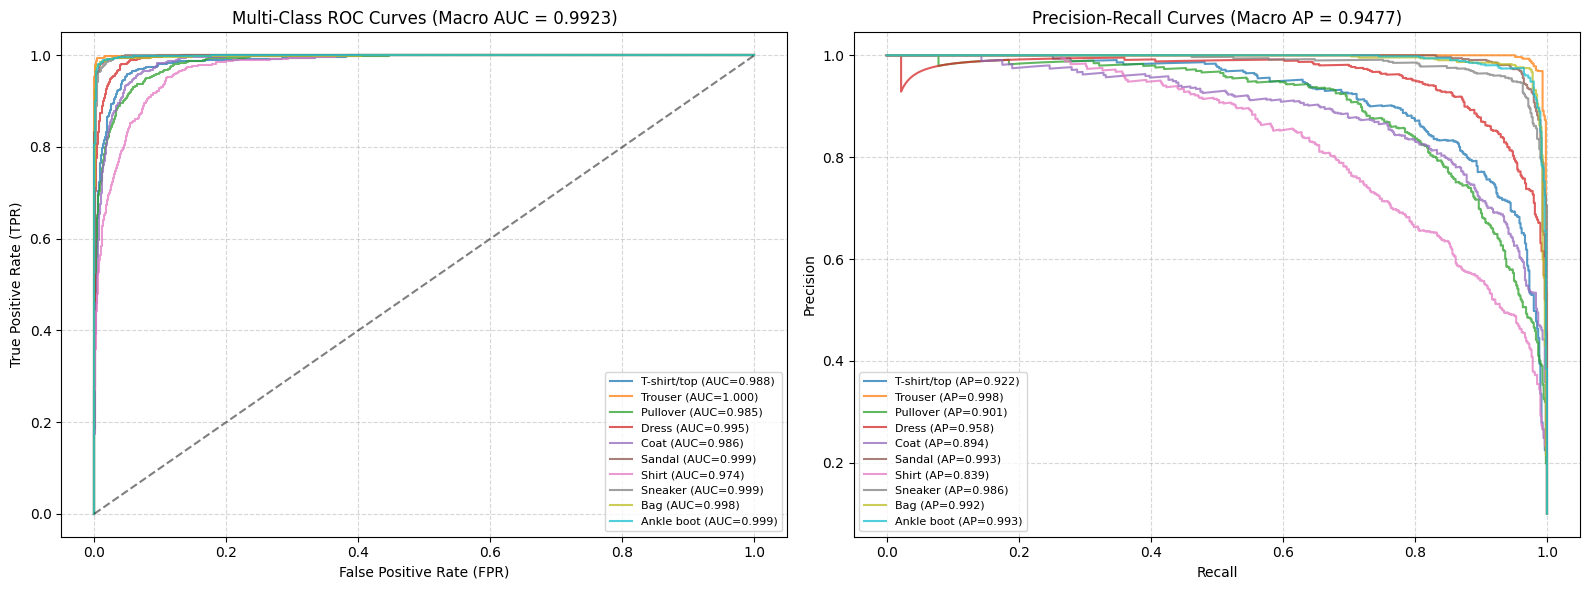

Macro ROC-AUC: 0.9923 | Macro Average Precision (PR-AUC): 0.9477


In [12]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

# Collect Softmax probabilities on the validation set
all_probas = []
all_targets = []
best_model.eval()
with torch.no_grad():
    for x_b, y_b in val_loader:
        logits = best_model(x_b.to(device))
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        all_probas.append(probs)
        all_targets.append(y_b.numpy())

all_probas = np.vstack(all_probas)
all_targets = np.concatenate(all_targets)
y_bin = label_binarize(all_targets, classes=list(range(10)))

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(16, 6))

# 1. ROC Curves
roc_aucs = []
for i in range(10):
    fpr, tpr, _ = roc_curve(y_bin[:, i], all_probas[:, i])
    score = auc(fpr, tpr)
    roc_aucs.append(score)
    ax_roc.plot(fpr, tpr, label=f"{CLASS_NAMES[i]} (AUC={score:.3f})", alpha=0.75)

macro_roc_auc = float(np.mean(roc_aucs))
ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax_roc.set_title(f"Multi-Class ROC Curves (Macro AUC = {macro_roc_auc:.4f})", fontsize=12)
ax_roc.set_xlabel("False Positive Rate (FPR)", fontsize=10)
ax_roc.set_ylabel("True Positive Rate (TPR)", fontsize=10)
ax_roc.legend(fontsize=8, loc="lower right")
ax_roc.grid(True, linestyle="--", alpha=0.5)

# 2. Precision-Recall Curves
ap_scores = []
for i in range(10):
    prec, rec, _ = precision_recall_curve(y_bin[:, i], all_probas[:, i])
    score = average_precision_score(y_bin[:, i], all_probas[:, i])
    ap_scores.append(score)
    ax_pr.plot(rec, prec, label=f"{CLASS_NAMES[i]} (AP={score:.3f})", alpha=0.75)

macro_ap = float(np.mean(ap_scores))
ax_pr.set_title(f"Precision-Recall Curves (Macro AP = {macro_ap:.4f})", fontsize=12)
ax_pr.set_xlabel("Recall", fontsize=10)
ax_pr.set_ylabel("Precision", fontsize=10)
ax_pr.legend(fontsize=8, loc="lower left")
ax_pr.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print(f"Macro ROC-AUC: {macro_roc_auc:.4f} | Macro Average Precision (PR-AUC): {macro_ap:.4f}")
